# Doses de vacina: 1ª dose, 2ª dose, reforço e dose única

Este notebook explora a base `vacinas_analitico.csv` para ajudar o cidadão a **entender o que significam os tipos de dose registrados** (1ª dose, 2ª dose, reforço, dose única etc.) — sem transformar isso em acompanhamento de pessoa nenhuma.

## ⚠️ Aviso sobre os dados

- **A base não identifica pacientes.** O campo de identificação do paciente foi omitido/anonimizado na origem (G-MUS). Isso significa que **não é possível seguir o histórico de uma mesma pessoa** ao longo do tempo, nem saber se ela "completou o esquema vacinal", "abandonou" ou está "protegida".
- Cada linha é um **registro de aplicação** (um evento), não uma pessoa. A mesma pessoa pode gerar várias linhas (por exemplo, 1ª dose e depois 2ª dose), mas **não temos como ligar essas linhas entre si**.
- **Duplicidades exatas foram mantidas de propósito.** O relatório nativo do G-MUS pode gerar entradas idênticas para imunizantes aplicados no mesmo lote/período quando o identificador do paciente é retirado. Essas duplicidades foram preservadas para manter o volume real de procedimentos registrados na fonte — ou seja, **este notebook conta registros/procedimentos, não pessoas**.
- As datas de aplicação podem vir em formato completo (`DD/MM/AAAA`) ou agrupadas por mês/ano (`MM/AAAA`), refletindo a digitação de carteirinhas físicas antigas. O código abaixo trata os dois formatos.
- A base não tem uma coluna de "sala" separada. A divisão organizacional disponível é o **bairro da unidade que aplicou a dose** (`nome_do_bairro`). Usamos essa coluna ao longo do notebook como o nível de "local de atendimento" mencionado nas perguntas orientadoras — ela agrupa unidades/postos, não pessoas.
- Existem alguns registros (poucos) com o campo de dose ausente, por divergência de preenchimento na origem. Eles são mostrados, não descartados.

**O que este notebook NÃO faz:** não calcula cobertura vacinal, não afirma abandono de esquema, não diz se uma pessoa está "vacinada" ou "protegida". Ele descreve **como os tipos de dose se distribuem** entre vacinas, bairros, estratégias e períodos — é uma leitura operacional da base, não uma leitura epidemiológica individual.


## Sumário
1. Preparação do ambiente
2. Visão geral da base
3. Padronizando o texto de dose (sem perder o original)
4. Tratando as datas de aplicação
5. **Pergunta 1** — Quais tipos de dose mais aparecem na base?
6. **Pergunta 2** — A composição de doses muda entre vacinas, bairros e períodos?
7. **Pergunta 3** — Há vacinas com muita 1ª dose e pouca 2ª dose (ou o inverso)?
8. **Pergunta 4** — Quais registros incompletos ou fora do padrão merecem atenção?
9. Exploração interativa (filtros por vacina, bairro, estratégia e ano)
10. Resumo para o cidadão

## 1. Preparação do ambiente

Se estiver rodando no **Google Colab**, faça upload do arquivo `vacinas_analitico.csv` quando solicitado (ou ajuste o caminho abaixo, se já subiu o arquivo para o Drive).

In [1]:
# Instala dependências (ipywidgets é necessário para os filtros interativos)
!pip install -q ipywidgets --upgrade


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 28.2 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import re
import os

pd.set_option('display.max_columns', None)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


In [3]:
CSV_PATH = "vacinas_analitico.csv"

if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print("Arquivo não encontrado localmente. Faça upload do CSV:")
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"Não encontrei '{CSV_PATH}'. Coloque o arquivo na mesma pasta do notebook "
            "ou rode isso no Google Colab para poder fazer upload."
        )

df = pd.read_csv(CSV_PATH)
print(f"Registros: {len(df):,} | Colunas: {list(df.columns)}")
df.head()


Arquivo não encontrado localmente. Faça upload do CSV:


Saving vacinas_analitico.csv to vacinas_analitico.csv
Registros: 30,883 | Colunas: ['nome_do_bairro', 'nome_da_vacina', 'codigo_da_vacina', 'estrategia', 'codigo_da_estrategia', 'dose', 'codigo_da_dose', 'vacina_estrategia_e_dose', 'lote', 'validade_do_lote', 'data_da_aplicacao', 'origem']


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


## 2. Visão geral da base

Antes de falar de doses, um retrato rápido: quantos registros, quantos valores nulos, quantas vacinas, bairros e estratégias distintas existem.

In [4]:
print("Dimensão:", df.shape)
print()
print("Valores ausentes por coluna:")
print(df.isnull().sum())


Dimensão: (30883, 12)

Valores ausentes por coluna:
nome_do_bairro                0
nome_da_vacina                0
codigo_da_vacina              0
estrategia                    0
codigo_da_estrategia          0
dose                          9
codigo_da_dose                9
vacina_estrategia_e_dose      0
lote                          0
validade_do_lote              0
data_da_aplicacao           860
origem                      860
dtype: int64


In [5]:
resumo = pd.DataFrame({
    "valores distintos": [
        df['nome_da_vacina'].nunique(),
        df['nome_do_bairro'].nunique(),
        df['estrategia'].nunique(),
        df['dose'].nunique(),
        df['origem'].nunique(),
    ]
}, index=["vacinas", "bairros (unidades/salas)", "estratégias", "textos de dose distintos", "origem do registro"])
resumo


,valores distintos
vacinas,41
bairros (unidades/salas),15
estratégias,12
textos de dose distintos,27
origem do registro,3


## 3. Padronizando o texto de dose (sem perder o original)

O campo `dose` vem em texto livre, com muitas variações (`1ª DOSE`, `ÚNICA`, `REFORÇO`, `2º REFORÇO`, `1ª DOSE DOBRADA`, `exposição - 3ª DOSE`, `DOSE ZERO`, `REVACINAÇÃO`, etc.). Para poder comparar, criamos colunas **novas** derivadas por regras (expressões regulares), mas **a coluna original `dose` é mantida intacta** — nada é sobrescrito ou perdido.

Novas colunas criadas:
- `dose_categoria`: agrupamento legível (1ª DOSE, 2ª DOSE, 3ª DOSE+, REFORÇO, DOSE ÚNICA, DOSE ZERO, REVACINAÇÃO, PROFILAXIA/TRATAMENTO, DOSE SEM ESPECIFICAÇÃO, NÃO INFORMADA)
- `dose_numero`: o número da dose/reforço quando existe (1, 2, 3, 4...)
- `dose_dobrada`: `True` quando o texto indica dose dobrada
- `dose_pos_exposicao`: `True` quando o texto indica contexto de pós-exposição

In [6]:
def parse_dose(texto):
    if pd.isnull(texto):
        return pd.Series({
            "dose_categoria": "NÃO INFORMADA",
            "dose_numero": np.nan,
            "dose_dobrada": False,
            "dose_pos_exposicao": False,
        })
    t = str(texto).upper()
    dobrada = "DOBRADA" in t
    exposicao = "EXPOSIÇÃO" in t or "EXPOSICAO" in t

    num_match = re.search(r"(\d+)[ºªA]?\s*(DOSE|REFORÇO|REFORCO)", t)
    numero = int(num_match.group(1)) if num_match else None

    if "ÚNICA" in t or "UNICA" in t:
        cat = "DOSE ÚNICA"
    elif "ZERO" in t:
        cat = "DOSE ZERO"
    elif "REVACINAÇÃO" in t or "REVACINACAO" in t:
        cat = "REVACINAÇÃO"
    elif "REFORÇO" in t or "REFORCO" in t:
        cat = "REFORÇO"
    elif "PROFILAXIA" in t or "TRATAMENTO" in t:
        cat = "PROFILAXIA/TRATAMENTO"
    elif numero == 1:
        cat = "1ª DOSE"
    elif numero == 2:
        cat = "2ª DOSE"
    elif numero and numero >= 3:
        cat = "3ª DOSE OU MAIS"
    elif t.strip() == "DOSE":
        cat = "DOSE (SEM ESPECIFICAÇÃO)"
    else:
        cat = "OUTRO/NÃO PADRONIZADO"

    return pd.Series({
        "dose_categoria": cat,
        "dose_numero": numero,
        "dose_dobrada": dobrada,
        "dose_pos_exposicao": exposicao,
    })

dose_info = df["dose"].apply(parse_dose)
df = pd.concat([df, dose_info], axis=1)

print("Checagem: nenhuma linha perdeu o texto original de dose ->",
      df["dose"].isnull().sum() == df["dose_categoria"].eq("NÃO INFORMADA").sum())

df[["dose", "dose_categoria", "dose_numero", "dose_dobrada", "dose_pos_exposicao"]].sample(8, random_state=1)


Checagem: nenhuma linha perdeu o texto original de dose -> True


,dose,dose_categoria,dose_numero,dose_dobrada,dose_pos_exposicao
482,ÚNICA,DOSE ÚNICA,NaN,False,False
6945,ÚNICA,DOSE ÚNICA,NaN,False,False
95,ÚNICA,DOSE ÚNICA,NaN,False,False
29793,ÚNICA,DOSE ÚNICA,NaN,False,False
17617,DOSE,DOSE (SEM ESPECIFICAÇÃO),NaN,False,False
19415,ÚNICA,DOSE ÚNICA,NaN,False,False
8723,ÚNICA,DOSE ÚNICA,NaN,False,False
18329,ÚNICA,DOSE ÚNICA,NaN,False,False


In [7]:
# Quantos registros caíram em cada categoria padronizada, e quais textos originais formam cada uma
tabela_categorias = (
    df.groupby("dose_categoria")["dose"]
    .agg(registros="count", exemplos_de_texto_original=lambda s: sorted(s.dropna().unique())[:5])
    .sort_values("registros", ascending=False)
)
tabela_categorias


,registros,exemplos_de_texto_original
dose_categoria,,
DOSE ÚNICA,17021,[ÚNICA]
1ª DOSE,4882,"[1ª DOSE, 1ª DOSE DOBRADA]"
2ª DOSE,3199,"[2ª DOSE, 2ª DOSE DOBRADA, exposição - 2ª DOSE]"
REFORÇO,2732,"[1º REFORÇO, 2º REFORÇO, REFORÇO]"
3ª DOSE OU MAIS,1356,"[3ª DOSE, 3ª DOSE DOBRADA, 4ª DOSE, 4ª DOSE DO..."
DOSE (SEM ESPECIFICAÇÃO),1244,[DOSE]
REVACINAÇÃO,235,"[1ª DOSE REVACINAÇÃO, 2ª DOSE REVACINAÇÃO, 2ª ..."
PROFILAXIA/TRATAMENTO,104,[PROFILAXIA/TRATAMENTO COM 1 FRASCO-AMPOLA/AMP...
DOSE ZERO,101,[DOSE ZERO]


### Paleta de cores fixa por categoria de dose

Para que a **mesma cor sempre represente a mesma categoria** em todos os gráficos deste notebook — o que é essencial para comparar vacina com vacina, bairro com bairro, estratégia com estratégia e ano com ano — definimos abaixo uma paleta fixa e duas funções auxiliares, usadas em todos os gráficos de composição de dose a partir daqui.

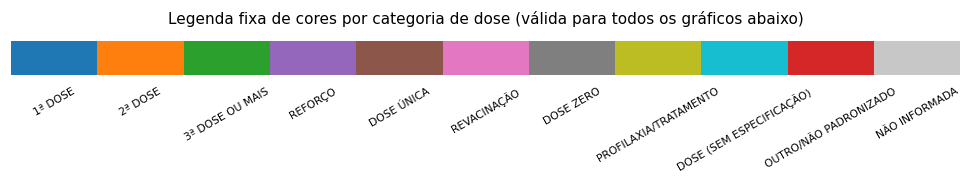

In [8]:
CATEGORY_ORDER = [
    "1ª DOSE",
    "2ª DOSE",
    "3ª DOSE OU MAIS",
    "REFORÇO",
    "DOSE ÚNICA",
    "REVACINAÇÃO",
    "DOSE ZERO",
    "PROFILAXIA/TRATAMENTO",
    "DOSE (SEM ESPECIFICAÇÃO)",
    "OUTRO/NÃO PADRONIZADO",
    "NÃO INFORMADA",
]

CATEGORY_COLORS = {
    "1ª DOSE": "#1f77b4",
    "2ª DOSE": "#ff7f0e",
    "3ª DOSE OU MAIS": "#2ca02c",
    "REFORÇO": "#9467bd",
    "DOSE ÚNICA": "#8c564b",
    "REVACINAÇÃO": "#e377c2",
    "DOSE ZERO": "#7f7f7f",
    "PROFILAXIA/TRATAMENTO": "#bcbd22",
    "DOSE (SEM ESPECIFICAÇÃO)": "#17becf",
    "OUTRO/NÃO PADRONIZADO": "#d62728",
    "NÃO INFORMADA": "#c7c7c7",
}

def ordenar_categorias(tabela):
    """Reordena as colunas de uma tabela (vacina x categoria, bairro x categoria etc.)
    sempre na mesma ordem de categorias, para friso visual consistente entre gráficos."""
    ordem_presente = [c for c in CATEGORY_ORDER if c in tabela.columns]
    extras = [c for c in tabela.columns if c not in CATEGORY_ORDER]
    return tabela[ordem_presente + extras]

def cores_para(colunas):
    """Devolve a lista de cores fixas correspondente a uma lista/índice de categorias."""
    return [CATEGORY_COLORS.get(c, "#999999") for c in colunas]

# Legenda visual única de referência: a partir daqui, toda categoria aparece sempre com a mesma cor
fig, ax = plt.subplots(figsize=(9, 1.6))
for i, cat in enumerate(CATEGORY_ORDER):
    ax.barh(0, 1, left=i, color=CATEGORY_COLORS[cat])
    ax.text(i + 0.5, -0.65, cat, ha="center", va="top", fontsize=7, rotation=30)
ax.set_xlim(0, len(CATEGORY_ORDER))
ax.set_ylim(-1.3, 0.6)
ax.axis("off")
ax.set_title("Legenda fixa de cores por categoria de dose (válida para todos os gráficos abaixo)", fontsize=10)
plt.tight_layout()
plt.show()


## 4. Tratando as datas de aplicação (`DD/MM/AAAA` ou `MM/AAAA`)

Criamos `ano_aplicacao` e `ano_mes_aplicacao` (período `AAAA-MM`) que funcionam para os dois formatos. Quando o dia não existe (registro só com mês/ano), ele simplesmente não é usado — só o ano e o mês.

In [9]:
def extrai_periodo(data_txt):
    if pd.isnull(data_txt):
        return pd.Series({"ano_aplicacao": np.nan, "ano_mes_aplicacao": np.nan})
    s = str(data_txt).strip()
    m_completo = re.match(r"^(\d{2})/(\d{2})/(\d{4})$", s)
    m_mes_ano = re.match(r"^(\d{2})/(\d{4})$", s)
    if m_completo:
        _, mes, ano = m_completo.groups()
    elif m_mes_ano:
        mes, ano = m_mes_ano.groups()
    else:
        return pd.Series({"ano_aplicacao": np.nan, "ano_mes_aplicacao": np.nan})
    return pd.Series({"ano_aplicacao": int(ano), "ano_mes_aplicacao": f"{ano}-{mes}"})

periodo_info = df["data_da_aplicacao"].apply(extrai_periodo)
df = pd.concat([df, periodo_info], axis=1)

print("Registros sem data interpretável:", df["ano_mes_aplicacao"].isnull().sum())
df[["data_da_aplicacao", "ano_aplicacao", "ano_mes_aplicacao"]].dropna().sample(5, random_state=2)


Registros sem data interpretável: 860


,data_da_aplicacao,ano_aplicacao,ano_mes_aplicacao
8733,01/04/2026,2026.0,2026-04
14550,01/06/2026,2026.0,2026-06
8357,01/03/2026,2026.0,2026-03
24423,01/05/2026,2026.0,2026-05
2151,01/04/2026,2026.0,2026-04


## 5. Pergunta 1 — Quais tipos de dose mais aparecem na base?

Dois olhares: o texto **original** de dose (como veio na origem) e a categoria **padronizada** (agrupada pelas regras acima).

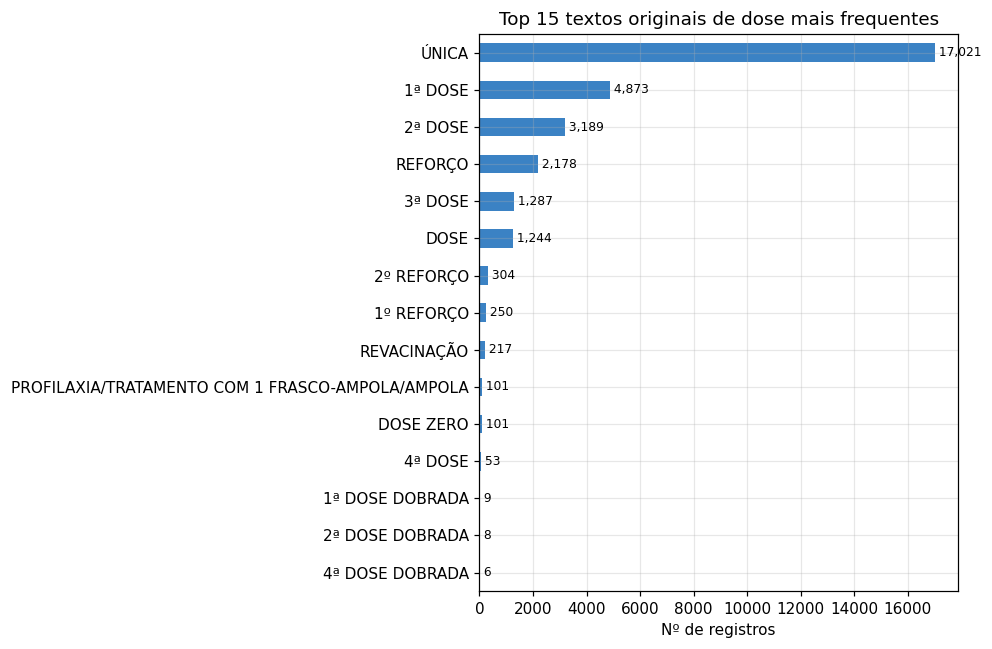

In [10]:
top_original = df["dose"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9, 6))
top_original.sort_values().plot(kind="barh", ax=ax, color="#3B82C4")
ax.set_title("Top 15 textos originais de dose mais frequentes")
ax.set_xlabel("Nº de registros")
ax.set_ylabel("")
for i, v in enumerate(top_original.sort_values()):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()


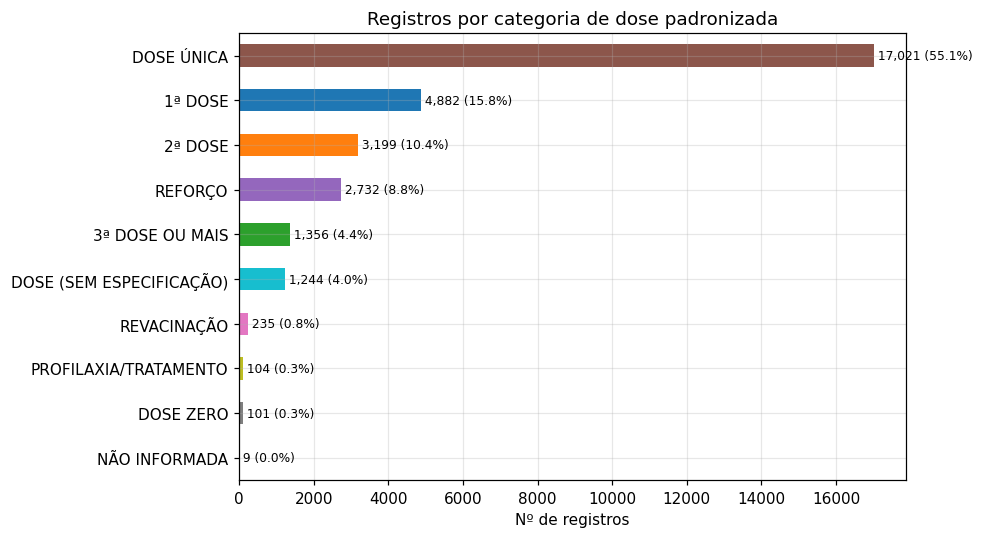

In [11]:
cat_counts = df["dose_categoria"].value_counts()
cat_counts_sorted = cat_counts.sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
cat_counts_sorted.plot(kind="barh", ax=ax, color=cores_para(cat_counts_sorted.index))
ax.set_title("Registros por categoria de dose padronizada")
ax.set_xlabel("Nº de registros")
ax.set_ylabel("")
for i2, v in enumerate(cat_counts_sorted):
    ax.text(v, i2, f" {v:,} ({v/len(df):.1%})", va="center", fontsize=8)
plt.tight_layout()
plt.show()


**Leitura:** a categoria `DOSE ÚNICA` domina a base — isso é esperado, já que muitas vacinas do calendário (febre amarela, HPV em alguns esquemas, algumas campanhas) são registradas assim por padrão de sistema, não porque "poucas pessoas tomaram a 2ª dose". Comparar `DOSE ÚNICA` com `1ª/2ª dose` só faz sentido **dentro da mesma vacina**, que é o que fazemos a seguir.

## 6. Pergunta 2 — A composição de doses muda entre vacinas, bairros (unidades) e períodos?

### 6.1 Por vacina (top 12 mais aplicadas)

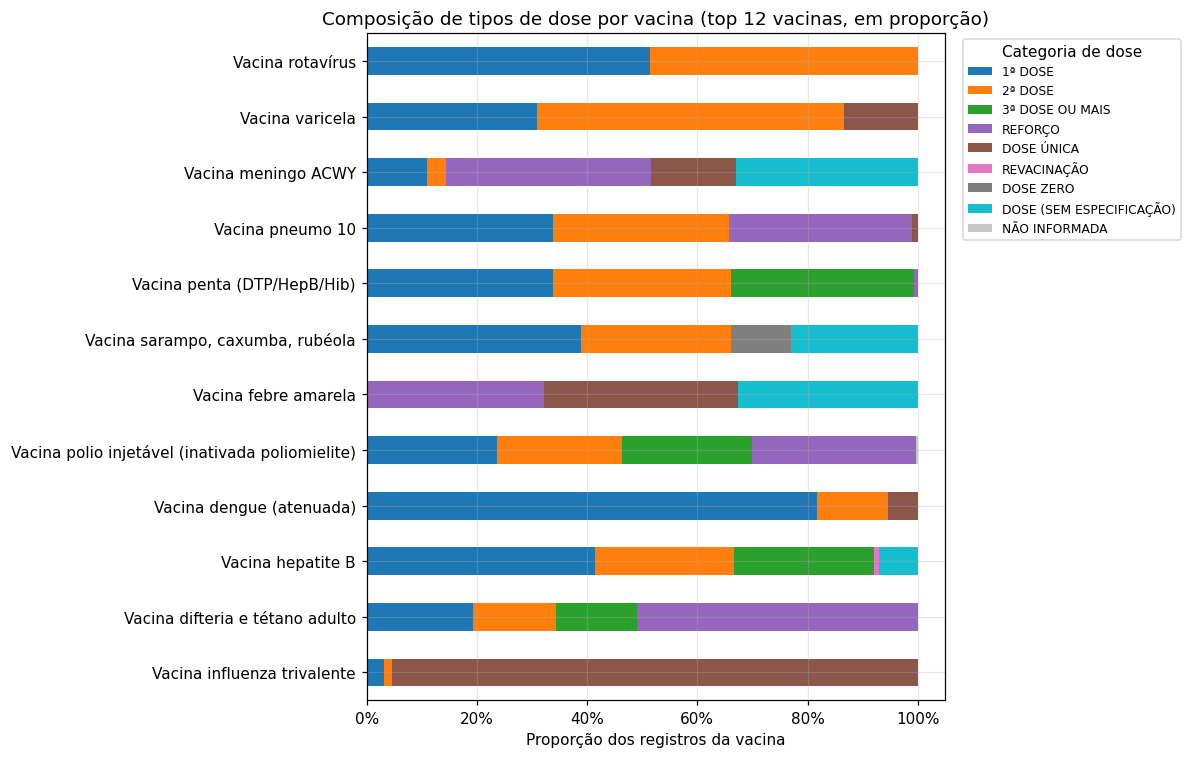

In [12]:
top_vacinas = df["nome_da_vacina"].value_counts().head(12).index

tab_vacina_dose = (
    df[df["nome_da_vacina"].isin(top_vacinas)]
    .groupby(["nome_da_vacina", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
    .loc[top_vacinas]
)
# proporção dentro de cada vacina, para comparar composição (não volume)
tab_vacina_prop = tab_vacina_dose.div(tab_vacina_dose.sum(axis=1), axis=0)
tab_vacina_prop = ordenar_categorias(tab_vacina_prop)

fig, ax = plt.subplots(figsize=(11, 7))
tab_vacina_prop.plot(kind="barh", stacked=True, ax=ax, color=cores_para(tab_vacina_prop.columns))
ax.set_title("Composição de tipos de dose por vacina (top 12 vacinas, em proporção)")
ax.set_xlabel("Proporção dos registros da vacina")
ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Categoria de dose")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()


### 6.2 Por bairro/unidade

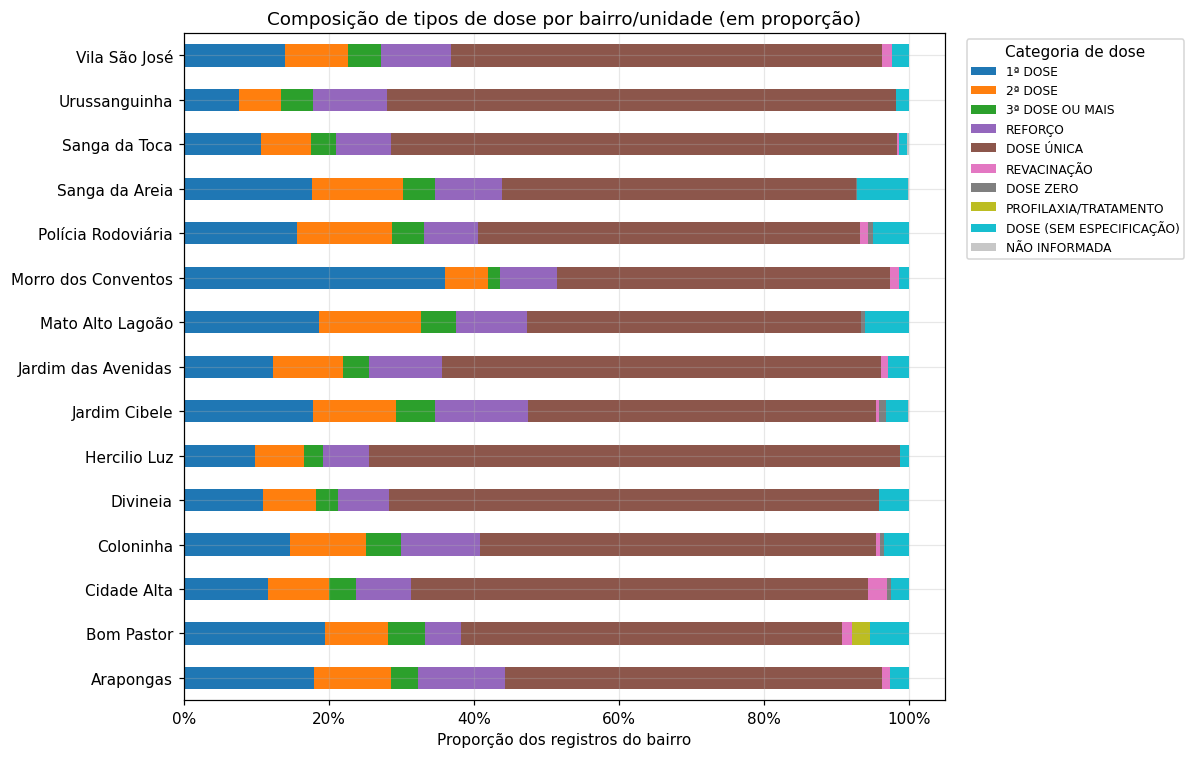

In [13]:
tab_bairro_dose = (
    df.groupby(["nome_do_bairro", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
)
tab_bairro_prop = tab_bairro_dose.div(tab_bairro_dose.sum(axis=1), axis=0)
tab_bairro_prop = ordenar_categorias(tab_bairro_prop)

fig, ax = plt.subplots(figsize=(11, 7))
tab_bairro_prop.plot(kind="barh", stacked=True, ax=ax, color=cores_para(tab_bairro_prop.columns))
ax.set_title("Composição de tipos de dose por bairro/unidade (em proporção)")
ax.set_xlabel("Proporção dos registros do bairro")
ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Categoria de dose")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()


### 6.3 Por estratégia de vacinação

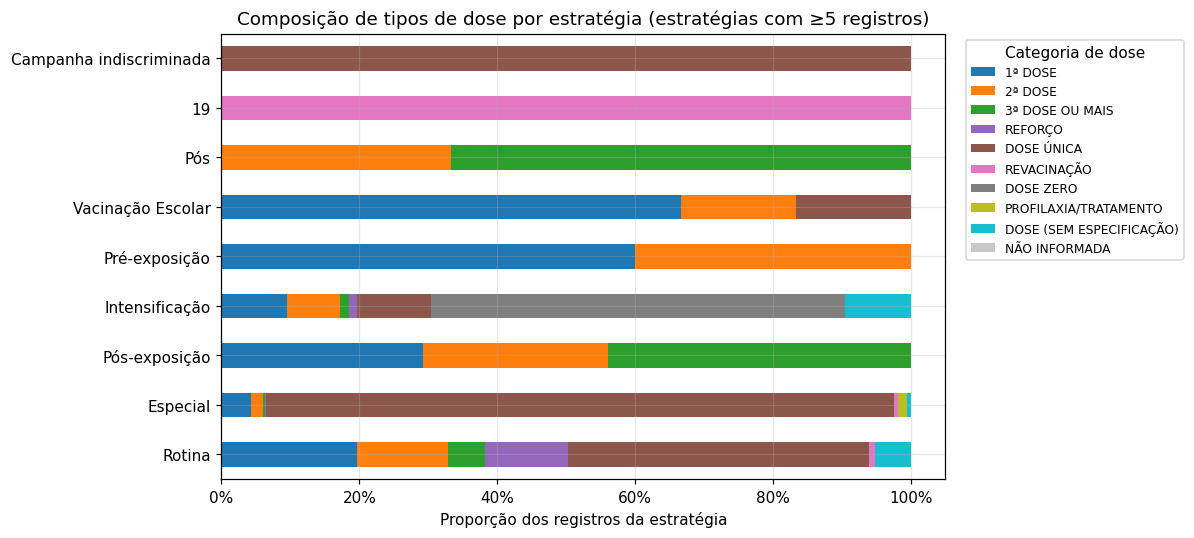

In [14]:
tab_estrategia_dose = (
    df.groupby(["estrategia", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
)
tab_estrategia_prop = tab_estrategia_dose.div(tab_estrategia_dose.sum(axis=1), axis=0)
tab_estrategia_prop = ordenar_categorias(tab_estrategia_prop)

# mantém só estratégias com volume razoável para o gráfico não ficar ilegível
estrategias_relevantes = tab_estrategia_dose.sum(axis=1).sort_values(ascending=False)
estrategias_relevantes = estrategias_relevantes[estrategias_relevantes >= 5].index

fig, ax = plt.subplots(figsize=(11, 5))
tab_estrategia_prop.loc[estrategias_relevantes].plot(kind="barh", stacked=True, ax=ax, color=cores_para(tab_estrategia_prop.columns))
ax.set_title("Composição de tipos de dose por estratégia (estratégias com ≥5 registros)")
ax.set_xlabel("Proporção dos registros da estratégia")
ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Categoria de dose")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()


### 6.4 Ao longo do tempo (por ano)

Usamos o ano de aplicação (extraído tanto de datas completas quanto de datas só com mês/ano).

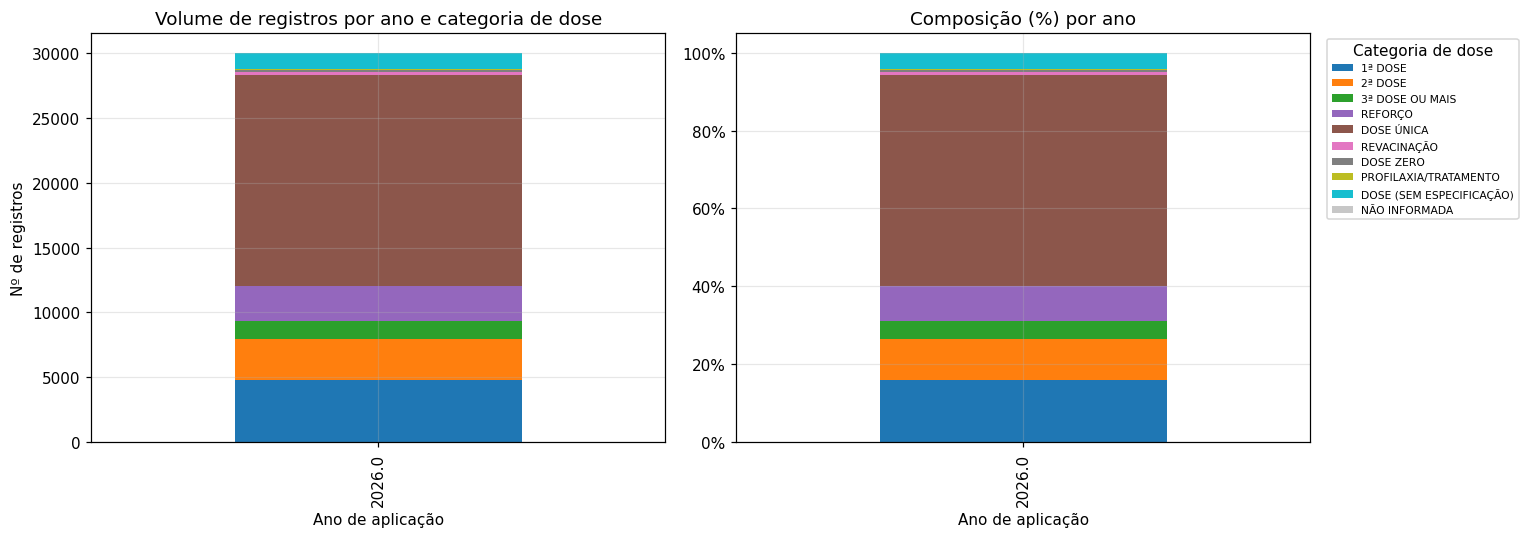

In [15]:
tab_ano_dose = (
    df.dropna(subset=["ano_aplicacao"])
    .groupby(["ano_aplicacao", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
tab_ano_dose = ordenar_categorias(tab_ano_dose)
tab_ano_prop = tab_ano_dose.div(tab_ano_dose.sum(axis=1), axis=0)
tab_ano_prop = ordenar_categorias(tab_ano_prop)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tab_ano_dose.plot(kind="bar", stacked=True, ax=axes[0], color=cores_para(tab_ano_dose.columns), legend=False)
axes[0].set_title("Volume de registros por ano e categoria de dose")
axes[0].set_xlabel("Ano de aplicação")
axes[0].set_ylabel("Nº de registros")

tab_ano_prop.plot(kind="bar", stacked=True, ax=axes[1], color=cores_para(tab_ano_prop.columns))
axes[1].set_title("Composição (%) por ano")
axes[1].set_xlabel("Ano de aplicação")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, title="Categoria de dose")

plt.tight_layout()
plt.show()


**Leitura:** mudanças na composição de dose por vacina, bairro, estratégia ou ano refletem principalmente **o desenho de cada calendário vacinal e o mix de público atendido em cada unidade/período** (ex.: uma unidade que atendeu mais campanha de gripe terá mais "DOSE ÚNICA"; um ano com campanha de reforço de covid terá mais "REFORÇO"). Isso **não indica, por si só**, qualidade de atendimento nem comportamento dos pacientes.

## 7. Pergunta 3 — Há vacinas com muita 1ª dose e pouca 2ª dose (ou o inverso)?

Aqui olhamos, **dentro de cada vacina**, a razão entre o nº de registros de `2ª DOSE` e `1ª DOSE`.

⚠️ **Importante:** como a base é anônima e tem registros por evento (não por pessoa), essa razão **não mede abandono de esquema vacinal nem adesão**. Uma razão baixa pode significar: vacina introduzida recentemente (ainda não houve tempo de 2ª dose), calendário com intervalo longo entre doses, mudança de estratégia, ou simplesmente menor demanda no período coberto pelos dados — entre outras explicações que a base sozinha não permite distinguir.

In [16]:
doses_1_2 = (
    df[df["dose_categoria"].isin(["1ª DOSE", "2ª DOSE"])]
    .groupby(["nome_da_vacina", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
)
# só vacinas que têm pelo menos 1ª dose registrada e volume mínimo para o número fazer sentido
doses_1_2 = doses_1_2[doses_1_2.get("1ª DOSE", 0) >= 10].copy()
doses_1_2["razao_2a_sobre_1a"] = doses_1_2.get("2ª DOSE", 0) / doses_1_2["1ª DOSE"]
doses_1_2 = doses_1_2.sort_values("razao_2a_sobre_1a")

doses_1_2


dose_categoria,1ª DOSE,2ª DOSE,razao_2a_sobre_1a
nome_da_vacina,,,
Vacina pneumo 13,18,1,0.055556
Vacina pneumo 23,85,11,0.129412
Vacina hepatite A adulto,29,4,0.137931
Vacina dengue (atenuada),1017,161,0.158309
Vacina HPV quadrivalente,46,12,0.260870
Vacina hexa (DTPa/HepB/VIP/Hib),10,3,0.300000
Vacina Hib,70,21,0.300000
Vacina meningo ACWY,76,24,0.315789
Vacina influenza trivalente,485,227,0.468041


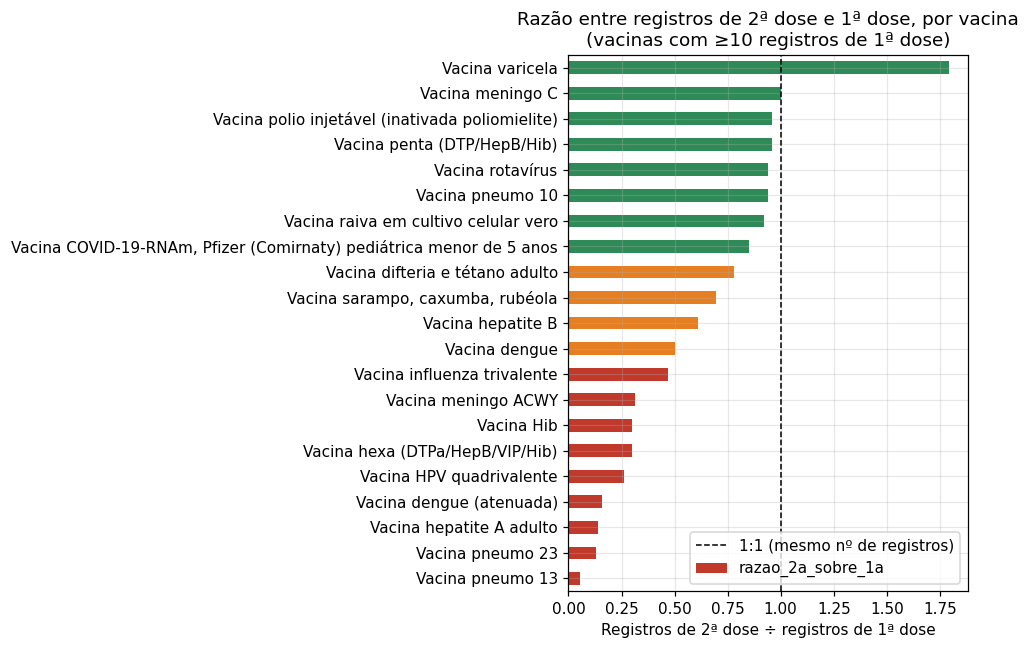

Vacinas com razão mais baixa (mais 1ª dose do que 2ª dose, em nº de registros):
nome_da_vacina
Vacina pneumo 13            0.055556
Vacina pneumo 23            0.129412
Vacina hepatite A adulto    0.137931
Vacina dengue (atenuada)    0.158309
Vacina HPV quadrivalente    0.260870
Name: razao_2a_sobre_1a, dtype: float64

Vacinas com razão mais alta (mais 2ª dose do que 1ª dose, em nº de registros):
nome_da_vacina
Vacina rotavírus                                   0.942492
Vacina penta (DTP/HepB/Hib)                        0.957143
Vacina polio injetável (inativada poliomielite)    0.957597
Vacina meningo C                                   1.003774
Vacina varicela                                    1.792929
Name: razao_2a_sobre_1a, dtype: float64


In [17]:
fig, ax = plt.subplots(figsize=(9, 6))
cores = ["#C0392B" if r < 0.5 else ("#E67E22" if r < 0.85 else "#2E8B57") for r in doses_1_2["razao_2a_sobre_1a"]]
doses_1_2["razao_2a_sobre_1a"].plot(kind="barh", ax=ax, color=cores)
ax.axvline(1.0, color="black", linestyle="--", linewidth=1, label="1:1 (mesmo nº de registros)")
ax.set_title("Razão entre registros de 2ª dose e 1ª dose, por vacina\n(vacinas com ≥10 registros de 1ª dose)")
ax.set_xlabel("Registros de 2ª dose ÷ registros de 1ª dose")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.show()

print("Vacinas com razão mais baixa (mais 1ª dose do que 2ª dose, em nº de registros):")
print(doses_1_2["razao_2a_sobre_1a"].head(5))
print()
print("Vacinas com razão mais alta (mais 2ª dose do que 1ª dose, em nº de registros):")
print(doses_1_2["razao_2a_sobre_1a"].tail(5))


**Como ler o gráfico:** barras vermelhas/laranjas têm muito mais registros de 1ª dose do que de 2ª dose; barras verdes têm quantidades próximas (ou mais 2ª dose). Isso é um **retrato do volume de registros no período coberto pela base**, não um indicador de cobertura vacinal — repetimos esse ponto porque é fácil confundir os dois.

## 8. Pergunta 4 — Quais registros incompletos ou fora do padrão merecem atenção?

Aqui reunimos, de forma transparente, os pontos que a auditoria da base já sinalizou e outros que aparecem na exploração.

In [18]:
print(f"1) Registros com campo de dose ausente: {df['dose'].isnull().sum()}")
df[df["dose"].isnull()][["nome_do_bairro", "nome_da_vacina", "estrategia", "lote", "data_da_aplicacao", "origem"]]


1) Registros com campo de dose ausente: 9


,nome_do_bairro,nome_da_vacina,estrategia,lote,data_da_aplicacao,origem
1517,Bom Pastor,"NIRSEVIMABE 1,0ml",Especial,AZ250163,01/06/2026,Carteirinha
5072,Bom Pastor,Vacina polio injetável (inativada poliomielite),Rotina,X3H851V,12/03/2026,Carteirinha
13056,Jardim Cibele,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediá...",Rotina,NC5436,18/05/2026,Prontuário
15266,Jardim Cibele,"Vacina sarampo, caxumba, rubéola e varicela",Rotina (1),258VVV008N,05/05/2026,Prontuário
16933,Jardim das Avenidas,Vacina polio injetável (inativada poliomielite),Rotina,X3H841V,01/02/2026,Carteirinha
22508,Polícia Rodoviária,Vacina Vírus Sincicial A e B (recombinante),Rotina,MG5689,25/03/2026,Carteirinha
25583,Sanga da Areia,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",Rotina (1),MT7306,01/03/2026,Carteirinha
26986,Sanga da Toca,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",Rotina,MT7306,01/05/2026,Carteirinha
27855,Sanga da Toca,Vacina polio injetável (inativada poliomielite),Rotina,X3H851V,01/04/2026,Carteirinha


In [19]:
print(f"2) Registros com data de aplicação ausente ou fora dos padrões esperados: "
      f"{df['ano_mes_aplicacao'].isnull().sum()}")
df[df["ano_mes_aplicacao"].isnull()][["nome_do_bairro", "nome_da_vacina", "dose", "data_da_aplicacao", "origem"]].head(10)


2) Registros com data de aplicação ausente ou fora dos padrões esperados: 860


,nome_do_bairro,nome_da_vacina,dose,data_da_aplicacao,origem
21889,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21890,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21891,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21892,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21893,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21894,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21895,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21896,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21897,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21898,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN


In [20]:
print("3) Registros marcados como 'dose dobrada' (poucos, mas fora do padrão usual):")
print(df["dose_dobrada"].sum(), "registros")
df[df["dose_dobrada"]][["nome_da_vacina", "dose", "estrategia", "nome_do_bairro"]]


3) Registros marcados como 'dose dobrada' (poucos, mas fora do padrão usual):
31 registros


,nome_da_vacina,dose,estrategia,nome_do_bairro
2428,Vacina hepatite B,1ª DOSE DOBRADA,Especial,Bom Pastor
2535,Vacina hepatite B,4ª DOSE DOBRADA,Especial,Bom Pastor
2541,Vacina hepatite B,3ª DOSE DOBRADA,Especial,Bom Pastor
2542,Vacina hepatite B,4ª DOSE REVACINAÇÃO DOBRADA,Especial,Bom Pastor
2551,Vacina hepatite B,4ª DOSE DOBRADA,Especial,Bom Pastor
2557,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2564,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2565,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2569,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2632,Vacina hepatite B,3ª DOSE DOBRADA,Especial,Bom Pastor


In [21]:
print("4) Registros de contexto pós-exposição misturados ao texto de dose:")
print(df["dose_pos_exposicao"].sum(), "registros")
df[df["dose_pos_exposicao"]][["nome_da_vacina", "dose", "estrategia"]]


4) Registros de contexto pós-exposição misturados ao texto de dose:
6 registros


,nome_da_vacina,dose,estrategia
28706,Vacina raiva em cultivo celular vero,exposição - 4ª DOSE,Pós
28707,Vacina raiva em cultivo celular vero,exposição - 3ª DOSE,Pós
28708,Vacina raiva em cultivo celular vero,exposição - 2ª DOSE,Pós
28709,Vacina raiva em cultivo celular vero,exposição - 4ª DOSE,Pós
28710,Vacina raiva em cultivo celular vero,exposição - 2ª DOSE,Pós
28711,Vacina raiva em cultivo celular vero,exposição - 3ª DOSE,Pós


In [22]:
print("5) Duplicidades exatas mantidas de propósito (linhas 100% iguais em todas as colunas originais):")
colunas_originais = ["nome_do_bairro", "nome_da_vacina", "codigo_da_vacina", "estrategia",
                      "codigo_da_estrategia", "dose", "codigo_da_dose", "vacina_estrategia_e_dose",
                      "lote", "validade_do_lote", "data_da_aplicacao", "origem"]
n_duplicadas = df.duplicated(subset=colunas_originais, keep=False).sum()
print(f"{n_duplicadas:,} registros fazem parte de algum grupo de duplicidade exata "
      f"({n_duplicadas/len(df):.1%} da base).")
print("Essas linhas NÃO foram removidas: como não há identificador de paciente, "
      "duplicidades exatas podem representar procedimentos distintos e legítimos "
      "(mesmo lote/dia/estratégia para pessoas diferentes). Remover reduziria o volume real.")


5) Duplicidades exatas mantidas de propósito (linhas 100% iguais em todas as colunas originais):
26,385 registros fazem parte de algum grupo de duplicidade exata (85.4% da base).
Essas linhas NÃO foram removidas: como não há identificador de paciente, duplicidades exatas podem representar procedimentos distintos e legítimos (mesmo lote/dia/estratégia para pessoas diferentes). Remover reduziria o volume real.


In [23]:
print("6) Estratégias com nomenclatura pouco clara (fora do vocabulário padrão de estratégias):")
estrategias_estranhas = df["estrategia"].value_counts()
estrategias_estranhas


6) Estratégias com nomenclatura pouco clara (fora do vocabulário padrão de estratégias):


,count
estrategia,
Rotina,22646
Especial,7791
Pós-exposição,239
Intensificação,168
Pré-exposição,10
Vacinação Escolar,6
Pós,6
Campanha indiscriminada,5
19,5


## 9. Exploração interativa

Use os filtros abaixo para explorar a composição de doses por **vacina**, **bairro**, **estratégia** e **período (ano)** — sem nunca sair do nível agregado (não há como escolher "uma pessoa").

In [24]:
import ipywidgets as widgets
from IPython.display import display, clear_output

vacina_opcoes = ["(todas)"] + sorted(df["nome_da_vacina"].dropna().unique().tolist())
bairro_opcoes = ["(todos)"] + sorted(df["nome_do_bairro"].dropna().unique().tolist())
estrategia_opcoes = ["(todas)"] + sorted(df["estrategia"].dropna().unique().tolist())
anos_disponiveis = sorted(df["ano_aplicacao"].dropna().unique().tolist())

w_vacina = widgets.Dropdown(options=vacina_opcoes, description="Vacina:", layout=widgets.Layout(width="420px"))
w_bairro = widgets.Dropdown(options=bairro_opcoes, description="Bairro:", layout=widgets.Layout(width="420px"))
w_estrategia = widgets.Dropdown(options=estrategia_opcoes, description="Estratégia:", layout=widgets.Layout(width="420px"))
w_ano = widgets.SelectionRangeSlider(
    options=[int(a) for a in anos_disponiveis] if anos_disponiveis else [0],
    index=(0, len(anos_disponiveis) - 1) if anos_disponiveis else (0, 0),
    description="Anos:",
    layout=widgets.Layout(width="420px"),
)
out = widgets.Output()

def atualizar(*args):
    with out:
        clear_output(wait=True)
        dados = df.copy()
        if w_vacina.value != "(todas)":
            dados = dados[dados["nome_da_vacina"] == w_vacina.value]
        if w_bairro.value != "(todos)":
            dados = dados[dados["nome_do_bairro"] == w_bairro.value]
        if w_estrategia.value != "(todas)":
            dados = dados[dados["estrategia"] == w_estrategia.value]
        if anos_disponiveis:
            ano_min, ano_max = w_ano.value
            dados = dados[(dados["ano_aplicacao"].isna()) | dados["ano_aplicacao"].between(ano_min, ano_max)]

        print(f"Registros no filtro: {len(dados):,} de {len(df):,} "
              f"({len(dados)/len(df):.1%} da base)")

        if len(dados) == 0:
            print("Nenhum registro para essa combinação de filtros.")
            return

        contagem = dados["dose_categoria"].value_counts().sort_values()
        fig, ax = plt.subplots(figsize=(8, 4.5))
        contagem.plot(kind="barh", ax=ax, color=cores_para(contagem.index))
        titulo_partes = []
        if w_vacina.value != "(todas)": titulo_partes.append(w_vacina.value)
        if w_bairro.value != "(todos)": titulo_partes.append(w_bairro.value)
        if w_estrategia.value != "(todas)": titulo_partes.append(w_estrategia.value)
        titulo = " | ".join(titulo_partes) if titulo_partes else "Base completa"
        ax.set_title(f"Composição de dose — {titulo}")
        ax.set_xlabel("Nº de registros")
        for i, v in enumerate(contagem):
            ax.text(v, i, f" {v:,}", va="center", fontsize=8)
        plt.tight_layout()
        plt.show()

for w in (w_vacina, w_bairro, w_estrategia, w_ano):
    w.observe(atualizar, names="value")

display(widgets.VBox([
    widgets.HTML("<b>Filtros (lembrando: sempre agregados, nunca por pessoa)</b>"),
    w_vacina, w_bairro, w_estrategia, w_ano, out
]))
atualizar()


## 10. Resumo para o cidadão

- **1ª dose, 2ª dose, 3ª dose, reforço:** indicam a posição do imunizante dentro de um esquema de múltiplas aplicações previsto no calendário daquela vacina.
- **Dose única:** vacinas cujo esquema padrão é aplicado uma única vez (ex.: febre amarela, na maioria dos casos).
- **Reforço / 1º e 2º reforço:** doses adicionais aplicadas depois do esquema básico, para manter a proteção ao longo do tempo.
- **Revacinação:** nova aplicação fora do esquema-padrão, geralmente por indicação específica (perda de carteira, exposição, orientação médica).
- **Dose zero:** aplicação extra antes do esquema oficial começar, usada em situações específicas (ex.: bebês em contexto de surto).
- **Dose dobrada:** quantidade diferente do padrão, aplicada por indicação médica pontual.

O que este notebook mostrou é **como esses tipos de dose se distribuem** na base — por vacina, bairro, estratégia e ano — e **onde os dados têm lacunas ou peculiaridades** (dose ausente, duplicidades mantidas de propósito, datas em formatos diferentes).

**O que ele não mostra, porque a base não permite:** se uma pessoa específica está com o esquema completo, se "abandonou" a vacinação, ou qual é a cobertura vacinal real da população — isso exigiria ligar registros a indivíduos, o que foi deliberadamente removido para proteger a privacidade dos pacientes.
